In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000
study_hours = np.random.uniform(1, 10, n)
attendance_pct = np.random.uniform(50, 100, n)
branch = np.random.choice(['CE', 'IT', 'EC', 'ME'], n)

# real relationship + noise, so models have something to learn
score = (5 * study_hours) + (0.3 * attendance_pct) + np.random.normal(0, 8, n)
score = np.clip(score, 0, 100).round(1)

df = pd.DataFrame({
    'student_id': range(1, n+1),
    'study_hours': study_hours.round(1),
    'attendance_pct': attendance_pct.round(1),
    'score': score,
    'branch': branch
})

df.head()

,student_id,study_hours,attendance_pct,score,branch
0,1,4.4,59.3,43.8,ME
1,2,9.6,77.1,76.1,EC
2,3,7.6,93.6,70.5,EC
3,4,6.4,86.6,58.6,EC
4,5,2.4,90.3,37.5,ME


In [3]:
df.describe()

,student_id,study_hours,attendance_pct,score
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,5.413500,75.351200,49.758800
std,288.819436,2.630701,14.608042,15.773765
min,1.000000,1.000000,50.200000,11.200000
25%,250.750000,3.100000,62.075000,37.600000
50%,500.500000,5.500000,75.950000,49.900000
75%,750.250000,7.700000,88.000000,60.900000
max,1000.000000,10.000000,100.000000,89.600000


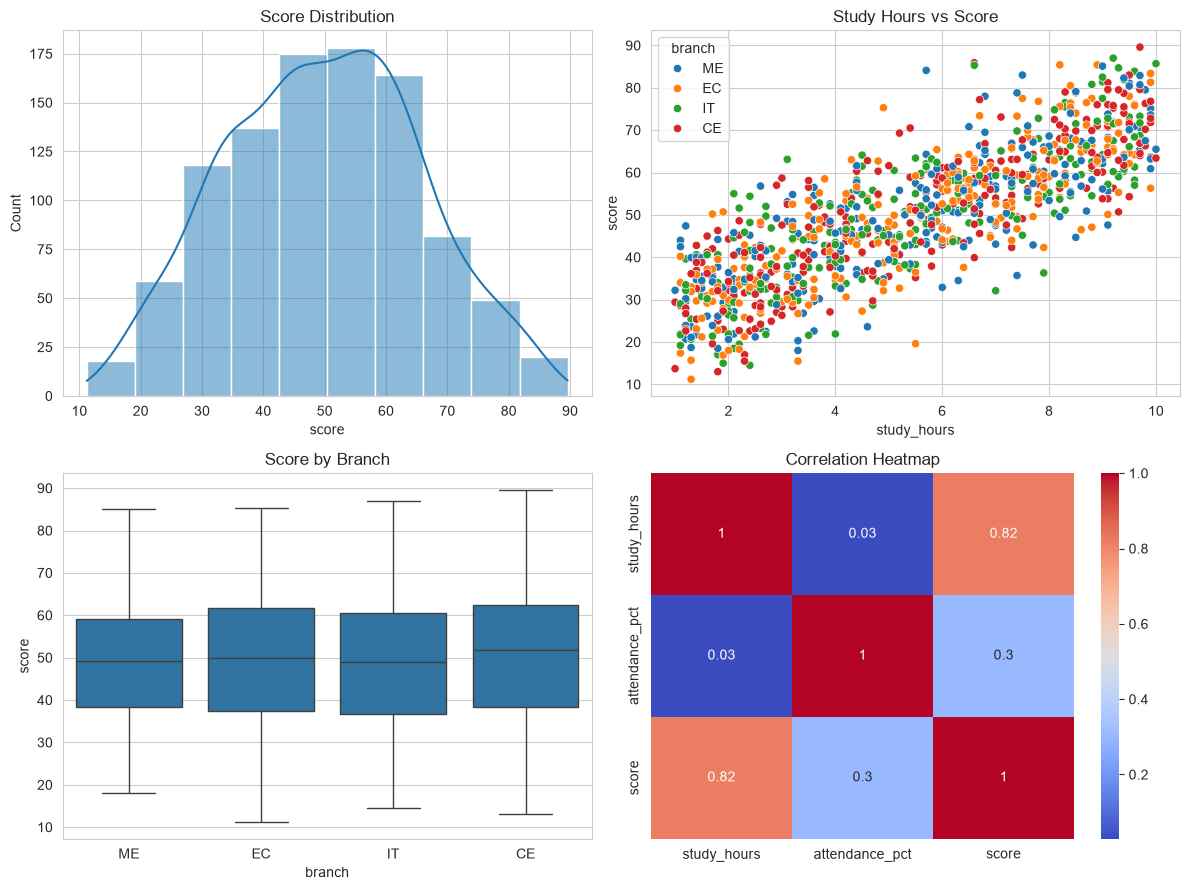

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Histogram of scores
sns.histplot(df['score'], bins=10, kde=True, ax=axes[0,0])
axes[0,0].set_title('Score Distribution')

# 2. Scatter: study hours vs score
sns.scatterplot(data=df, x='study_hours', y='score', hue='branch', ax=axes[0,1])
axes[0,1].set_title('Study Hours vs Score')

# 3. Boxplot: score by branch
sns.boxplot(data=df, x='branch', y='score', ax=axes[1,0])
axes[1,0].set_title('Score by Branch')

# 4. Correlation heatmap
sns.heatmap(df[['study_hours', 'attendance_pct', 'score']].corr(), annot=True, cmap='coolwarm', ax=axes[1,1])
axes[1,1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [5]:
correlations = df[['study_hours', 'attendance_pct', 'score']].corr()['score'].sort_values(ascending=False)
print(correlations)

score             1.000000
study_hours       0.821639
attendance_pct    0.304971
Name: score, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[['study_hours', 'attendance_pct']] 
y = df['score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
print(X_train_scaled)

[[-1.54062777  1.07486045]
 [ 1.53351171 -1.34517806]
 [ 0.39494153 -1.53028016]
 ...
 [ 0.96422662  0.89661398]
 [ 0.69856024 -1.66053719]
 [-0.62977163  1.26681817]]


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
preds_lr = lr.predict(X_test_scaled)

rmse_lr = mean_squared_error(y_test, preds_lr) ** 0.5
r2_lr = r2_score(y_test, preds_lr)
print(f"Linear Regression → RMSE: {rmse_lr:.2f}, R²: {r2_lr:.3f}")

Linear Regression → RMSE: 8.07, R²: 0.747


In [18]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_scaled, y_train)
preds_dt = dt.predict(X_test_scaled)

rmse_dt = mean_squared_error(y_test, preds_dt) ** 0.5
r2_dt = r2_score(y_test, preds_dt)
print(f"Decision Tree → RMSE: {rmse_dt:.2f}, R²: {r2_dt:.3f}")

Decision Tree → RMSE: 12.64, R²: 0.379


In [20]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
preds_knn = knn.predict(X_test_scaled)

rmse_knn = mean_squared_error(y_test, preds_knn) ** 0.5
r2_knn = r2_score(y_test, preds_knn)
print(f"KNN → RMSE: {rmse_knn:.2f}, R²: {r2_knn:.3f}")

KNN → RMSE: 8.90, R²: 0.692


In [21]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_scaled, y_train)
preds_rf = rf.predict(X_test_scaled)

rmse_rf = mean_squared_error(y_test, preds_rf) ** 0.5
r2_rf = r2_score(y_test, preds_rf)
print(f"Random Forest → RMSE: {rmse_rf:.2f}, R²: {r2_rf:.3f}")

Random Forest → RMSE: 9.10, R²: 0.678


In [22]:
from sklearn.svm import SVR

svr = SVR()
svr.fit(X_train_scaled, y_train)
preds_svr = svr.predict(X_test_scaled)

rmse_svr = mean_squared_error(y_test, preds_svr) ** 0.5
r2_svr = r2_score(y_test, preds_svr)
print(f"SVR → RMSE: {rmse_svr:.2f}, R²: {r2_svr:.3f}")

SVR → RMSE: 8.36, R²: 0.728


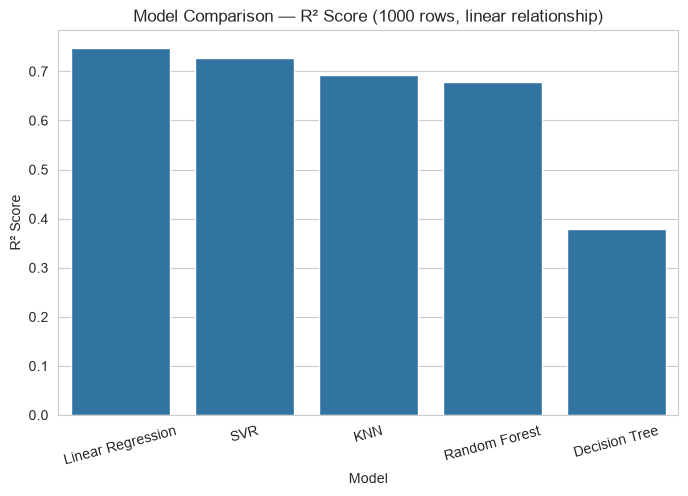

In [23]:
results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'SVR', 'KNN', 'Random Forest', 'Decision Tree'],
    'RMSE': [8.07, 8.36, 8.90, 9.10, 12.64],
    'R2': [0.747, 0.728, 0.692, 0.678, 0.379]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x='Model', y='R2', order=results_df.sort_values('R2', ascending=False)['Model'])
plt.title('Model Comparison — R² Score (1000 rows, linear relationship)')
plt.ylabel('R² Score')
plt.xticks(rotation=15)
plt.show()

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# create pass/fail column if not already there
df['result'] = (df['score'] >= 50).astype(int)

X = df[['study_hours', 'attendance_pct']]
y_class = df['result']

X_train, X_test, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVC': SVC()
}

results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train_c)          # ← y_train_c, not y_train
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test_c, preds)          # ← y_test_c, not y_test
    results.append({'Model': name, 'Accuracy': round(acc, 3)})

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
print(results_df)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


                 Model  Accuracy
0  Logistic Regression     0.855
4                  SVC     0.855
3                  KNN     0.845
2        Random Forest     0.835
1        Decision Tree     0.780


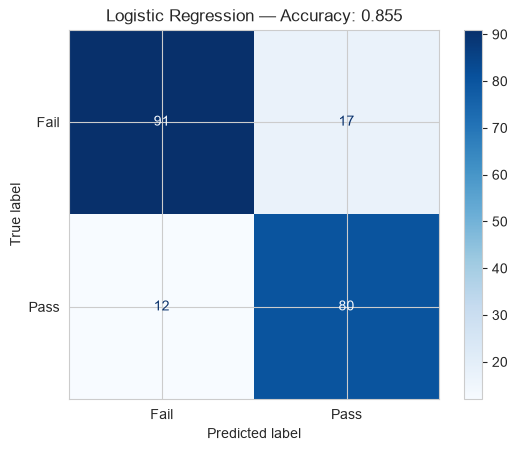

Logistic Regression — Classification Report:
      precision  recall  f1-score
Fail      0.883   0.843     0.863
Pass      0.825   0.870     0.847




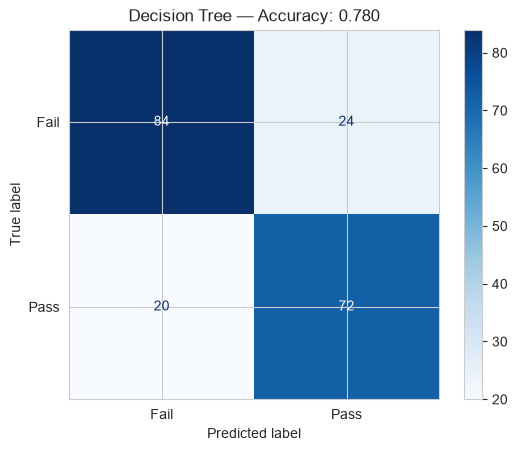

Decision Tree — Classification Report:
      precision  recall  f1-score
Fail      0.808   0.778     0.792
Pass      0.750   0.783     0.766




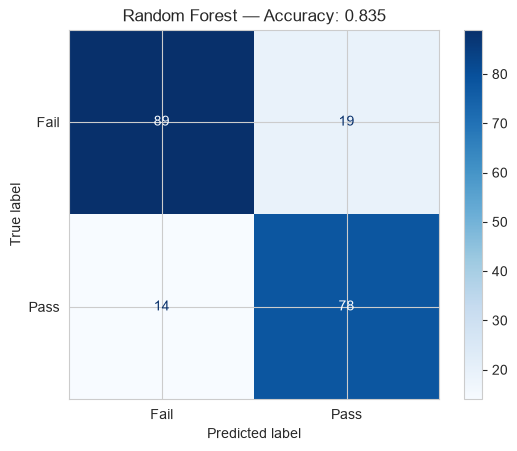

Random Forest — Classification Report:
      precision  recall  f1-score
Fail      0.864   0.824     0.844
Pass      0.804   0.848     0.825




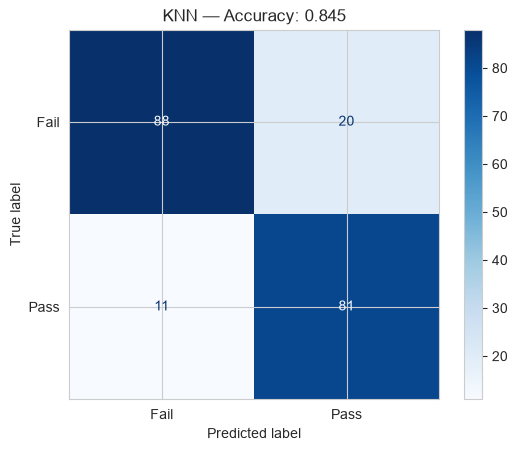

KNN — Classification Report:
      precision  recall  f1-score
Fail      0.889   0.815     0.850
Pass      0.802   0.880     0.839




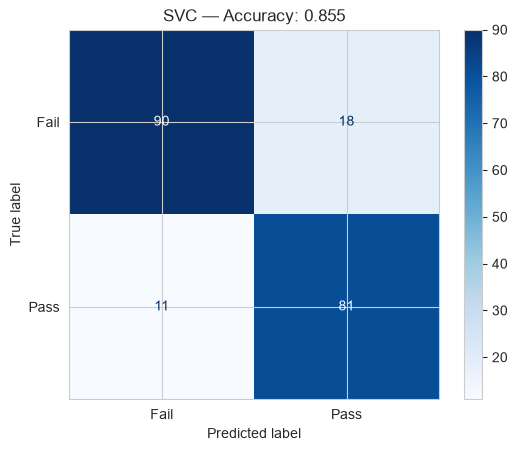

SVC — Classification Report:
      precision  recall  f1-score
Fail      0.891   0.833     0.861
Pass      0.818   0.880     0.848




In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import matplotlib.pyplot as plt
import pandas as pd

for name, model in models.items():
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test_c, preds)
    cm = confusion_matrix(y_test_c, preds)
    report = classification_report(y_test_c, preds, target_names=['Fail', 'Pass'], output_dict=True)
    report_df = pd.DataFrame(report).transpose().loc[['Fail', 'Pass'], ['precision', 'recall', 'f1-score']].round(3)
    
    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(cm, display_labels=['Fail', 'Pass'])
    disp.plot(cmap='Blues')
    plt.title(f'{name} — Accuracy: {acc:.3f}')
    plt.show()
    
    # Print precision/recall/f1 table
    print(f"{name} — Classification Report:")
    print(report_df)
    print("\n" + "="*50 + "\n")

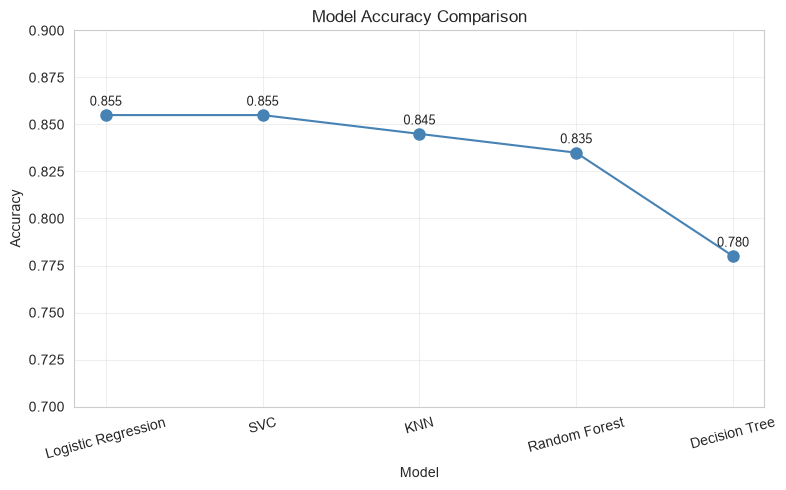

In [34]:
import matplotlib.pyplot as plt

results_df_sorted = results_df.sort_values('Accuracy', ascending=False)

plt.figure(figsize=(8, 5))
plt.plot(results_df_sorted['Model'], results_df_sorted['Accuracy'], marker='o', linestyle='-', color='steelblue', markersize=8)

for i, acc in enumerate(results_df_sorted['Accuracy']):
    plt.text(i, acc + 0.005, f'{acc:.3f}', ha='center', fontsize=9)

plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0.7, 0.9)
plt.xticks(rotation=15)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# HERE from above data logistic reggresion and  svc model perform best tie accuraccy .
# we assuming logestic reggresion best fit for this data cause of its simple implementation and easy to understand